In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a new approach to train deep neural...,0.3636,0.1017,0.1953,0.8715,0.8133,0.8414,2,7,8,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,We propose a novel deep learning framework for...,0.3711,0.0920,0.1831,0.8525,0.8234,0.8377,2,8,8,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,This paper presents a new approach to the prob...,0.2800,0.0505,0.1500,0.8528,0.8527,0.8528,2,8,8,37,False,36-40


In [2]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


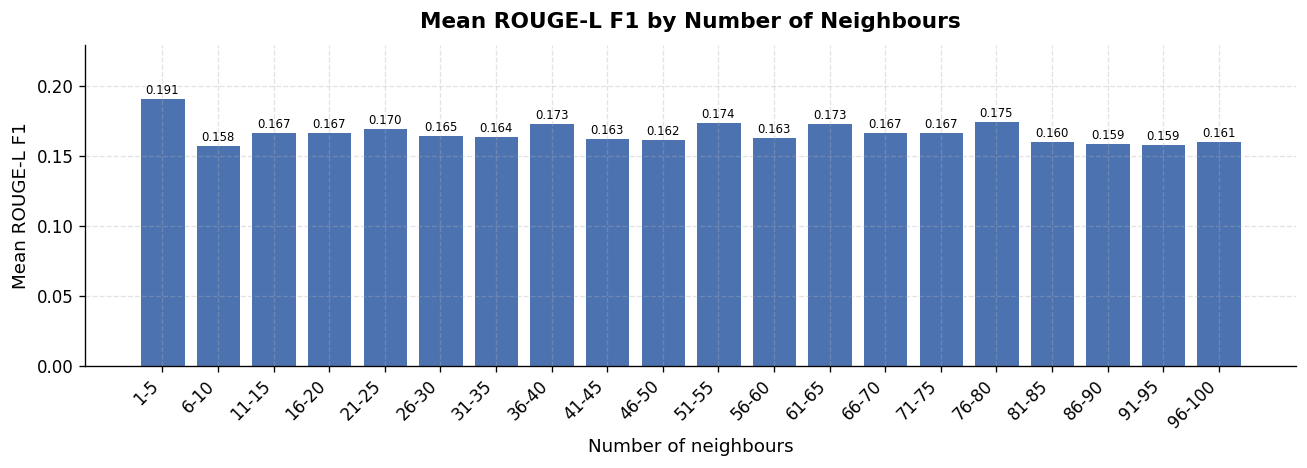

In [3]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

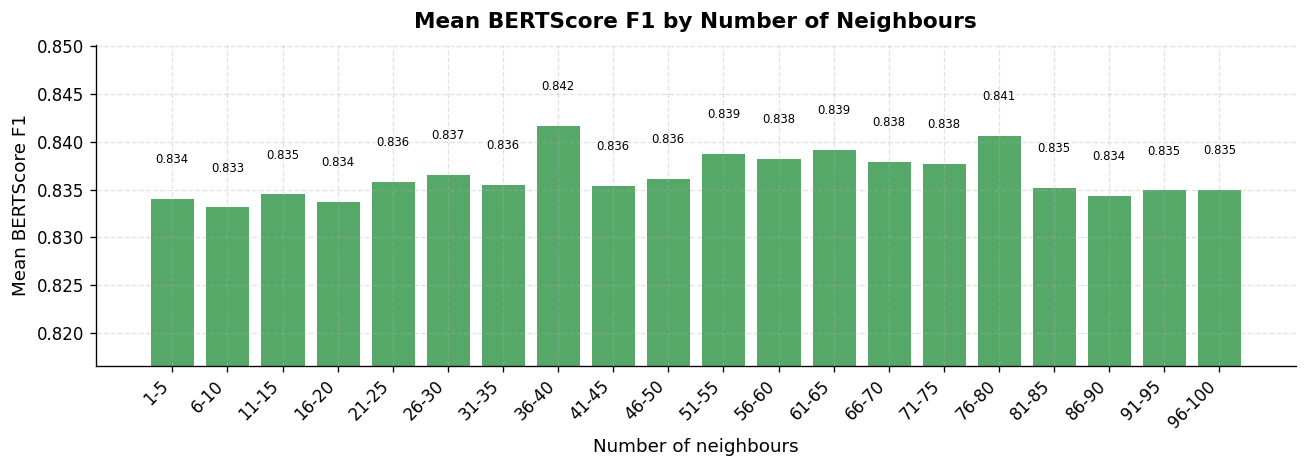

In [4]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

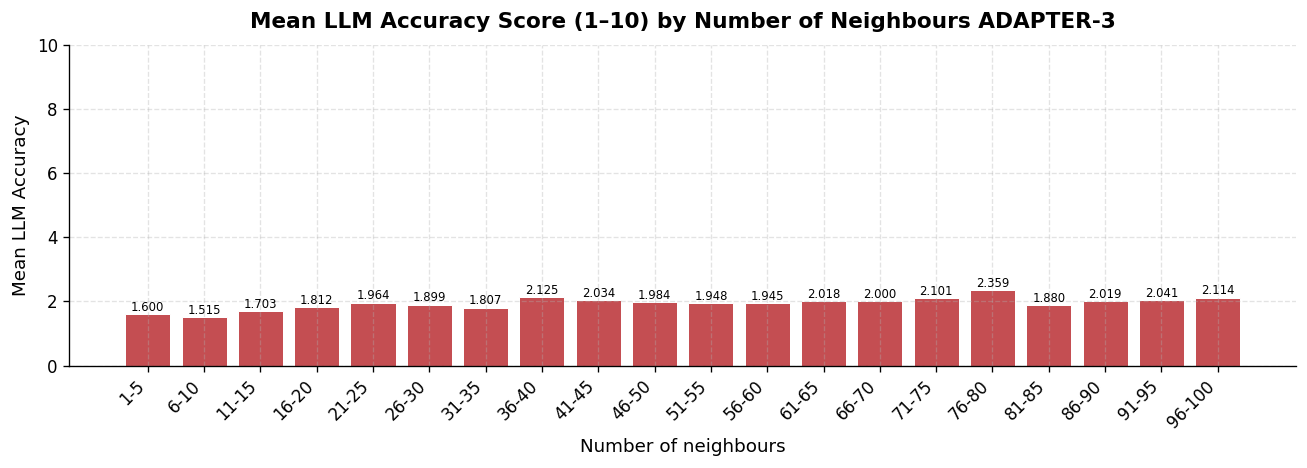

1.9544973544973545
2.0


In [5]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

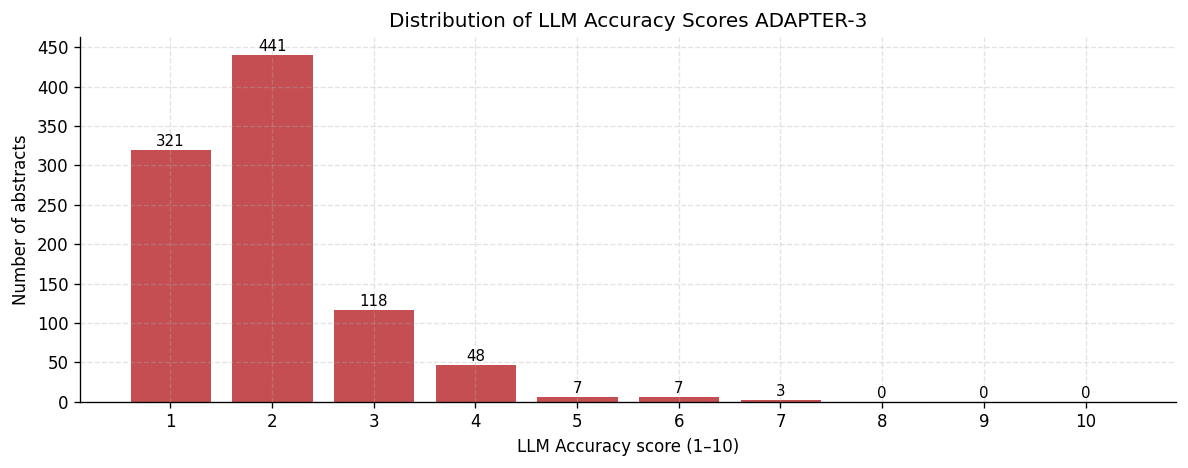

llm_accuracy
1     321
2     441
3     118
4      48
5       7
6       7
7       3
8       0
9       0
10      0
Name: count, dtype: int64

In [6]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

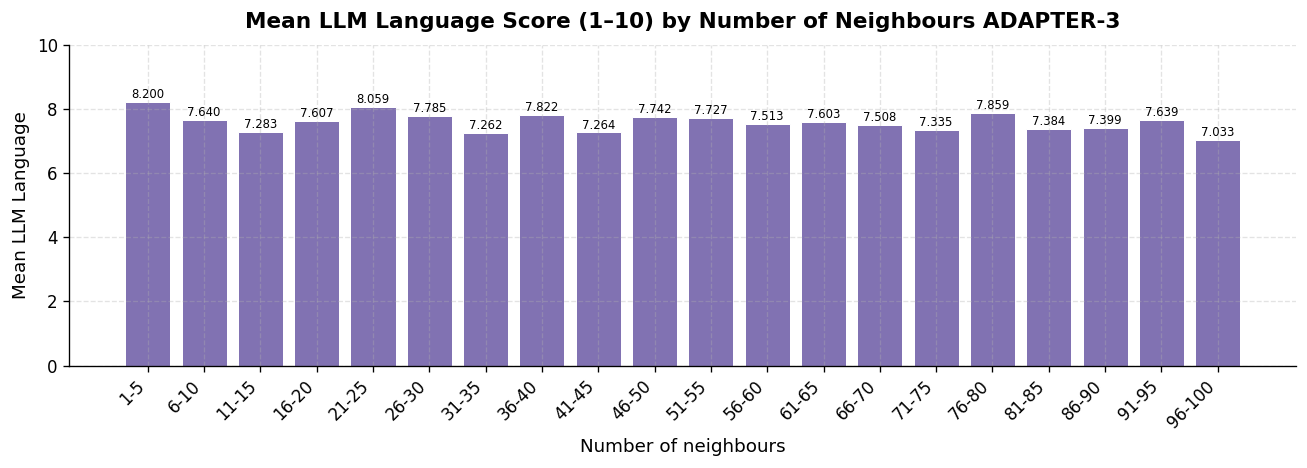

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

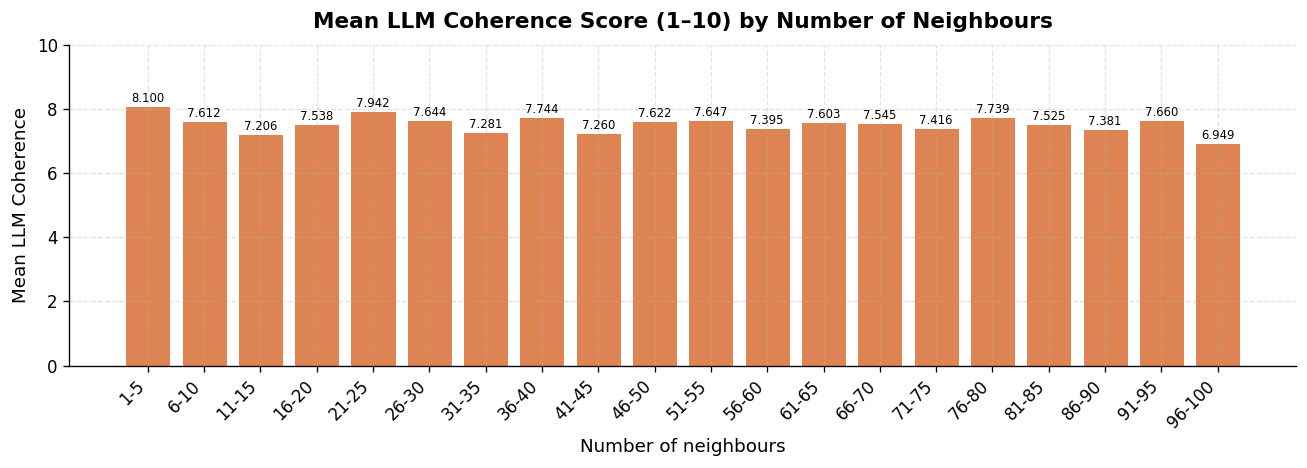

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

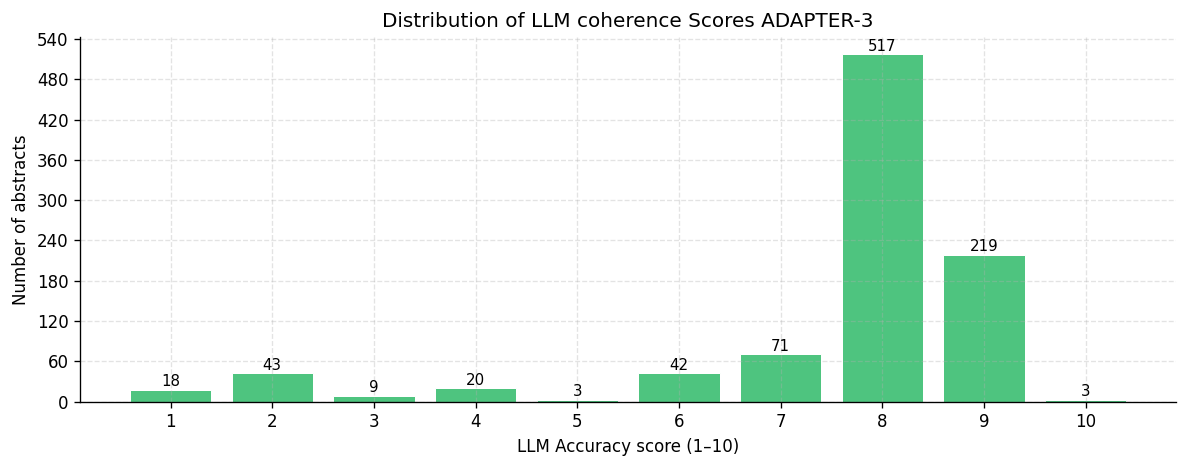

llm_coherence
1      18
2      43
3       9
4      20
5       3
6      42
7      71
8     517
9     219
10      3
Name: count, dtype: int64

In [9]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [10]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 61 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      1.9545
Mean llm_accuracy (excluding 1,2): 1.9966


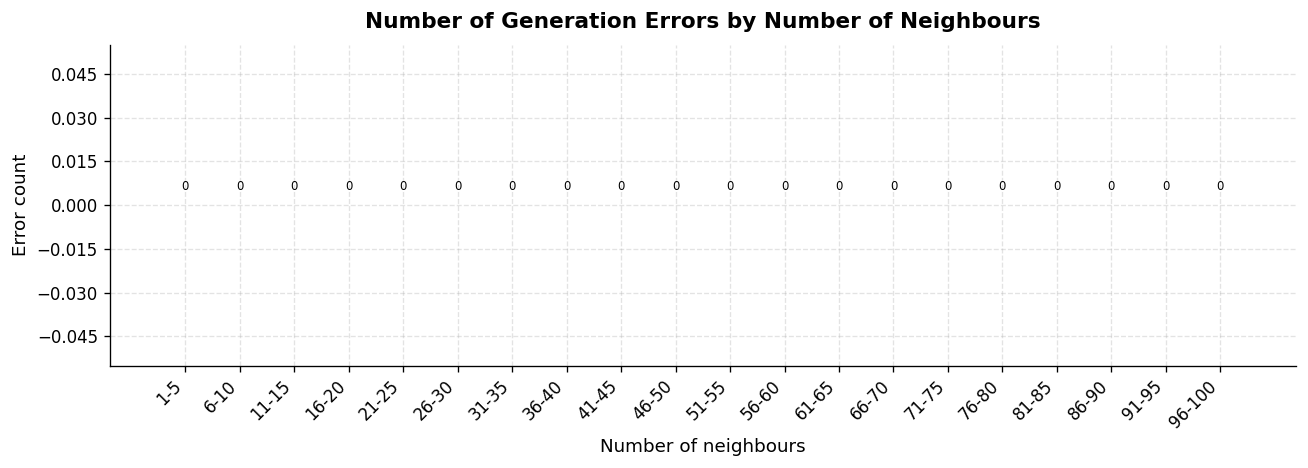

In [11]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [12]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_56764/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,168895,"We study the problem of approximate near neighbor (ANN) search and show the following results: #R##N#- An improved framework for solving the ANN problem using locality-sensitive hashing, reducing the number of evaluations of locality-sensitive hash functions and the word-RAM complexity compared to the standard framework. #R##N#- A framework for solving the ANN problem with space-time tradeoffs as well as tight upper and lower bounds for the space-time tradeoff of framework solutions to the ANN problem under cosine similarity. #R##N#- A novel approach to solving the ANN problem on sets along with a matching lower bound, improving the state of the art. #R##N#- A self-tuning version of the algorithm is shown through experiments to outperform existing similarity join algorithms. #R##N#- Tight lower bounds for asymmetric locality-sensitive hashing which has applications to the approximate furthest neighbor problem, orthogonal vector search, and annulus queries. #R##N#- A proof of the optimality of a well-known Boolean locality-sensitive hashing scheme. #R##N#We study the problem of efficient algorithms for producing high-quality pseudorandom numbers and obtain the following results: #R##N#- A deterministic algorithm for generating pseudorandom numbers of arbitrarily high quality in constant time using near-optimal space. #R##N#- A randomized construction of a family of hash functions that outputs pseudorandom numbers of arbitrarily high quality with space usage and running time nearly matching known cell-probe lower bounds.",We study the problem of maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small set of vertices that hits all the small cuts of a graph. We show that the problem is equivalent to maintaining a small,1
1,83197,"Aerial cinematography is revolutionizing industries that require live and dynamic camera viewpoints such as entertainment, sports, and security. However, safely piloting a drone while filming a moving target in the presence of obstacles is immensely taxing, often requiring multiple expert human operators. Hence, there is demand for an autonomous cinematographer that can reason about both geometry and scene context in real-time. Existing approaches do not address all aspects of this problem; they either require high-precision motion-capture systems or GPS tags to localize targets, rely on prior maps of the environment, plan for short time horizons, or only follow artistic guidelines specified before flight. #R##N#In this work, we address the problem in its entirety and pro

In [13]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_56764/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,140009,"In person re-identification (Re-ID), supervised methods usually need a large amount of expensive label information, while unsupervised ones are still unable to deliver satisfactory identification performance. In this paper, we introduce a novel person Re-ID task called unsupervised cross-camera person Re-ID, which only needs the within-camera (intra-camera) label information but not cross-camera (inter-camera) labels which are more expensive to obtain. In real-world applications, the intra-camera label information can be easily captured by tracking algorithms or few manual annotations. In this situation, the main challenge becomes the distribution discrepancy across different camera views, caused by the various body pose, occlusion, image resolution, illumination conditions, and background noises in different cameras. To address this situation, we propose a novel Adversarial Camera Alignment Network (ACAN) for unsupervised cross-camera person Re-ID. It consists of the camera-alignment task and the supervised within-camera learning task. To achieve the camera alignment, we develop a Multi-Camera Adversarial Learning (MCAL) to map images of different cameras into a shared subspace. Particularly, we investigate two different schemes, including the existing GRL (i.e., gradient reversal layer) scheme and the proposed scheme called ""other camera equiprobability"" (OCE), to conduct the multi-camera adversarial task. Based on this shared subspace, we then leverage the within-camera labels to train the network. Extensive experiments on five large-scale datasets demonstrate the superiority of ACAN over multiple state-of-the-art unsupervised methods that take advantage of labeled source domains and generated images by GAN-based models. In particular, we verify that the proposed multi-camera adversarial task does contribute to the significant improvement.","In this paper, we propose a novel deep learning framework for multi-label image classification. The proposed framework is based on a multi-task learning approach, where the tasks are the image classification labels. The framework is composed of two main components: a feature extractor and a multi-task classifier. The feature extractor is a deep convolutional neural network (CNN) that is trained to extract features from the input images. The multi-task classifier is a deep fully connected network that is trained to predict the image classification labels. The proposed framework is trained in a multi-task learning manner, where the loss function is a weighted sum of the losses of the individual tasks. The weights of the loss function are learned during the training process. The proposed framework is evaluated on the PASCAL VOC 2007 dataset, and the results show that the proposed framework outperforms the state-of-the-art methods.",1
1,134731,"This thesis focuses on process mining on event data where such a normative specification is absent and, as a result, the event data is less structured. The thesis puts special emphasis on one application domain that fits this description: the analysis of smart home data where sequences of daily activities are recorded. In this thesis we propose a set of techniques to analyze such data, which can be grouped into two categories of techniques. The first category of methods focuses on preprocessing event logs in order to enable process discovery techniques to extract insights into unstructured event data. In this category we have developed the following techniques: - An unsupervised approach to refine event labels based on the time at which the event took place, allowing for example to distinguish recorded eating events into breakfast, lunch, and dinner. - An approach to detect and filter from event logs so-called chaotic activities, which are activities that cause process discovery methods to overgeneralize. - A supervised approach to abstract low-level events into more high-level ev

In [14]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


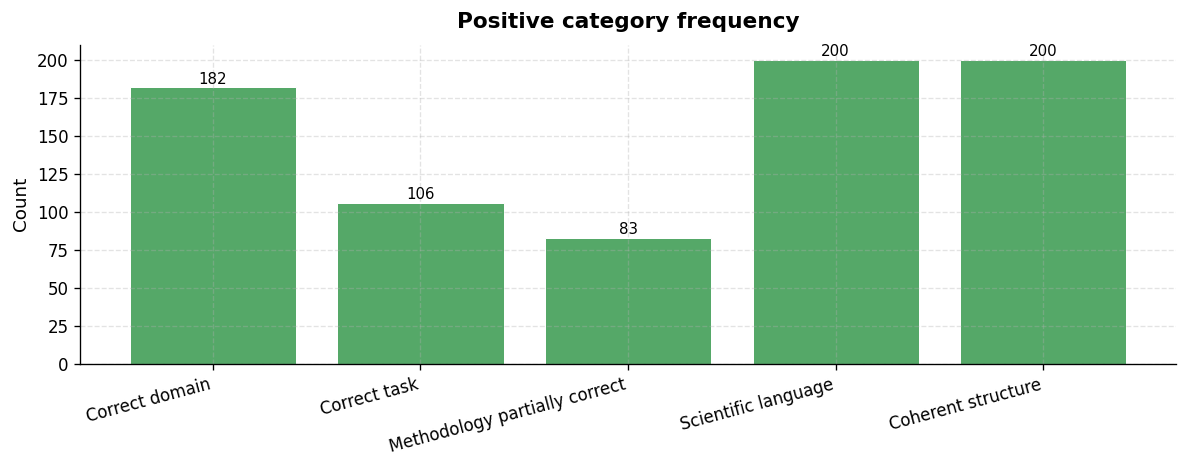

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()